# 03 Preprocessing

This notebook prepares the cleaned CredData lines for modeling in Phase 2. It reads `data/processed/credata_clean.csv` from `01_cleaning`, turns each row into numbers with `src/features.py`, splits the rows by repository, applies a log transform to the skewed length and position measures, and scales the numeric features with a scaler fitted on the train set only.

No model is trained here. Outputs show counts and summary numbers only, never `LineText` or `Value`, because the notebook is tracked by git.

## Setup

We import the libraries and add the `src` folder to the path so the notebook can use `load_data` and `build_features` from `src/features.py`. The notebook runs from the `notebooks` folder, so paths go up one level.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import MinMaxScaler, StandardScaler

# The notebook runs from the notebooks folder so src and data sit one level up
sys.path.insert(0, str(Path("..") / "src"))
from features import build_features, load_data

CLEAN_PATH = Path("..") / "data" / "processed" / "credata_clean.csv"
OUT_DIR = Path("..") / "data" / "processed"

# Colors for the train and test sets in every chart
TRAIN_COLOR = "#2a78d6"
TEST_COLOR = "#eb6834"
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

## Load the cleaned data and build features

`load_data` reads the cleaned file with `dtype=str` and `keep_default_na=False`, as agreed in `docs/CLEANED_DATA.md`, and turns `label` into a whole number. `build_features` works out every feature from its own row, so it can run before the split without letting test rows affect train rows.

In [2]:
df = load_data(CLEAN_PATH)
X = build_features(df)
print("rows:", len(df))
print("feature columns:", X.shape[1])
print("missing feature values:", int(X.isna().sum().sum()))
print("label 1 share:", round(df["label"].mean() * 100, 2), "percent")

rows: 66291
feature columns: 39
missing feature values: 0
label 1 share: 23.34 percent


All 66,291 cleaned rows give 39 features with no missing values, and 23.34 percent of rows are real secrets, the same share as in `01_cleaning`.

## Feature types

A feature that only takes the values 0 and 1 is a flag and is already on a common scale. The other features are counts, positions, ratios or entropy, and these are the ones that need a transform or scaling.

In [3]:
binary_cols = [c for c in X.columns if set(X[c].unique()) <= {0, 1}]
numeric_cols = [c for c in X.columns if c not in binary_cols]
print("flag features:", len(binary_cols))
print("numeric features:", len(numeric_cols))
print()
print(X[numeric_cols].describe().T[["min", "25%", "50%", "75%", "max"]].round(3).to_string())

flag features: 28
numeric features: 11

                    min   25%    50%       75%         max
value_len           0.0   0.0    0.0    30.000    6368.000
value_entropy       0.0   0.0    0.0     3.625       6.022
value_digit_ratio   0.0   0.0    0.0     0.162       1.000
value_upper_ratio   0.0   0.0    0.0     0.000       1.000
value_lower_ratio   0.0   0.0    0.0     0.417       1.000
value_symbol_ratio  0.0   0.0    0.0     0.062       1.000
line_len            9.0  38.0   58.0    95.000  711242.000
line_number         1.0  66.0  255.0  1688.000  917380.000
lines_spanned       1.0   1.0    1.0     1.000     106.000
var_name_len        0.0   3.0    8.0    13.000     214.000
path_depth          3.0   3.0    3.0     4.000      10.000


28 of the 39 features are flags. Most value measures have a median of 0 because about half of the rows have no value, where the whole line is marked. `line_len`, `line_number` and `value_len` have maximums thousands of times their medians, so they need a transform before scaling.

## Split by repository

Rows from the same repository share authors, file layout and often the same lines, so a model tested on a repository it has already seen would look better than it is. All rows of a repository therefore go to the same side of the split, with about 20 percent of rows in the test set.

`GroupShuffleSplit` picks 20 percent of repositories, not 20 percent of rows. `01_cleaning` found that the largest repository holds 15.4 percent of rows, so the share of rows in the test set depends a lot on the seed. We try 200 seeds and keep the one whose test set is closest to 20 percent of rows and to the overall share of real secrets. This choice only uses sizes and label shares, never feature values.

In [4]:
groups = df["RepoId"]
y = df["label"]
overall_share = y.mean()

candidates = []
for seed in range(200):
    train_idx, test_idx = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=seed).split(X, y, groups))
    test_rows = len(test_idx) / len(df)
    test_share = y.iloc[test_idx].mean()
    candidates.append({
        "seed": seed,
        "test_rows_percent": round(test_rows * 100, 2),
        "train_label_1_percent": round(y.iloc[train_idx].mean() * 100, 2),
        "test_label_1_percent": round(test_share * 100, 2),
        "distance": abs(test_rows - 0.2) + abs(test_share - overall_share),
    })
candidates = pd.DataFrame(candidates).sort_values("distance")
print("test rows percent over all seeds, min and max:",
      candidates["test_rows_percent"].min(), candidates["test_rows_percent"].max())
print()
print(candidates.head(5).round(4).to_string(index=False))

test rows percent over all seeds, min and max: 8.94 44.39

 seed  test_rows_percent  train_label_1_percent  test_label_1_percent  distance
   65              19.97                  23.36                 23.26    0.0011
  180              20.26                  23.42                 23.02    0.0058
   34              19.14                  23.34                 23.33    0.0086
  132              18.57                  23.25                 23.72    0.0182
  171              21.35                  23.61                 22.33    0.0236


Depending on the seed, the test set holds from 8.94 to 44.39 percent of rows, so a seed picked without checking could give a badly sized test set. Seed 65 gives 19.97 percent of rows and almost the same share of real secrets on both sides.

We apply the best seed and check the result: no repository on both sides, the sizes, and the label shares.

In [5]:
SPLIT_SEED = int(candidates.iloc[0]["seed"])
train_idx, test_idx = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SPLIT_SEED).split(X, y, groups))
train_df, test_df = df.iloc[train_idx], df.iloc[test_idx]
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]

print("seed:", SPLIT_SEED)
print("repositories in both sets:", len(set(train_df["RepoId"]) & set(test_df["RepoId"])))
summary = pd.DataFrame({
    "repositories": [train_df["RepoId"].nunique(), test_df["RepoId"].nunique()],
    "rows": [len(train_df), len(test_df)],
    "rows_percent": [round(len(train_df) / len(df) * 100, 2), round(len(test_df) / len(df) * 100, 2)],
    "label_1_percent": [round(train_df["label"].mean() * 100, 2), round(test_df["label"].mean() * 100, 2)],
}, index=["train", "test"])
print(summary.to_string())
print()
gt = pd.crosstab(df["GroundTruth"], np.where(df.index.isin(test_df.index), "test", "train"), colnames=["split"])
gt_percent = (gt / gt.sum() * 100).round(2)
print(pd.concat([gt, gt_percent.add_suffix(" percent")], axis=1).to_string())
largest_repo = df["RepoId"].value_counts().index[0]
print()
print("largest repository is in:", "test" if largest_repo in set(test_df["RepoId"]) else "train")

seed: 65
repositories in both sets: 0
       repositories   rows  rows_percent  label_1_percent
train           268  53056         80.03            23.36
test             67  13235         19.97            23.26



split        test  train  test percent  train percent
GroundTruth                                          
F            8786  38138         66.38          71.88
T            3078  12392         23.26          23.36
X            1371   2526         10.36           4.76

largest repository is in: train


No repository is on both sides. Train has 268 repositories and 53,056 rows, test has 67 repositories and 13,235 rows, and the share of real secrets is 23.36 against 23.26 percent. The largest repository is in train.

F and X are both label 0 but are not spread evenly: X is 10.36 percent of test rows against 4.76 percent of train rows. The test set has more test values and placeholders, which matters when reading false alarms in Phase 2.

## Line text shared between train and test

`01_cleaning` found 319 line texts that appear in more than one repository. If the same line sits in a train repository and a test repository, a model can score well on it by memory. We count these lines without printing them.

In [6]:
shared_text = set(train_df["LineText"]) & set(test_df["LineText"])
test_shared = test_df["LineText"].isin(shared_text)
print("distinct line texts in both sets:", len(shared_text))
print("train rows with such a text:", int(train_df["LineText"].isin(shared_text).sum()))
print("test rows with such a text:", int(test_shared.sum()),
      "(" + str(round(test_shared.mean() * 100, 2)) + " percent of test rows)")
print("label 1 share among those test rows:", round(test_df.loc[test_shared, "label"].mean() * 100, 2), "percent")

distinct line texts in both sets: 98
train rows with such a text: 360
test rows with such a text: 148 (1.12 percent of test rows)
label 1 share among those test rows: 0.0 percent


98 distinct line texts appear in both sets, on 148 test rows (1.12 percent of test rows). None of those test rows is a real secret, so remembering them could only help a model reject false alarms, not find secrets. The share is small, so the rows are kept, and Phase 2 can report test scores with and without them.

## Skew of the numeric features

Skewness measures how lopsided a distribution is. 0 means balanced, and values far above 1 mean a long tail to the right. `01_cleaning` decided to keep every outlier and apply a log transform to the length and position measures instead. We compare skewness on the train set before and after `log1p`, which is the log of one plus the value, so a value of 0 stays 0.

In [7]:
skew = pd.DataFrame({
    "skew_raw": X_train[numeric_cols].skew(),
    "skew_after_log1p": np.log1p(X_train[numeric_cols]).skew(),
}).round(2)
print(skew.to_string())

                    skew_raw  skew_after_log1p
value_len              33.94              0.34
value_entropy           0.24              0.07
value_digit_ratio       1.40              1.26
value_upper_ratio       3.29              3.00
value_lower_ratio       1.15              0.94
value_symbol_ratio      4.62              3.48
line_len               66.12              1.80
line_number             8.56              0.51
lines_spanned          14.86              8.60
var_name_len            3.10             -0.57
path_depth              1.35              1.00


`log1p` brings the skew of `value_len`, `line_len` and `line_number` much closer to 0 (0.34, 1.80 and 0.51). `lines_spanned` stays skewed at 8.60 because almost every row spans one line and a few span many, and a log cannot spread out a column that is nearly one value. The ratios and path depth are not length or position measures and their skew changes little.

The chart shows the four length and position measures on the train set before and after the log transform. The left column uses the raw value and the right column uses `log1p`. The vertical axis counts rows.

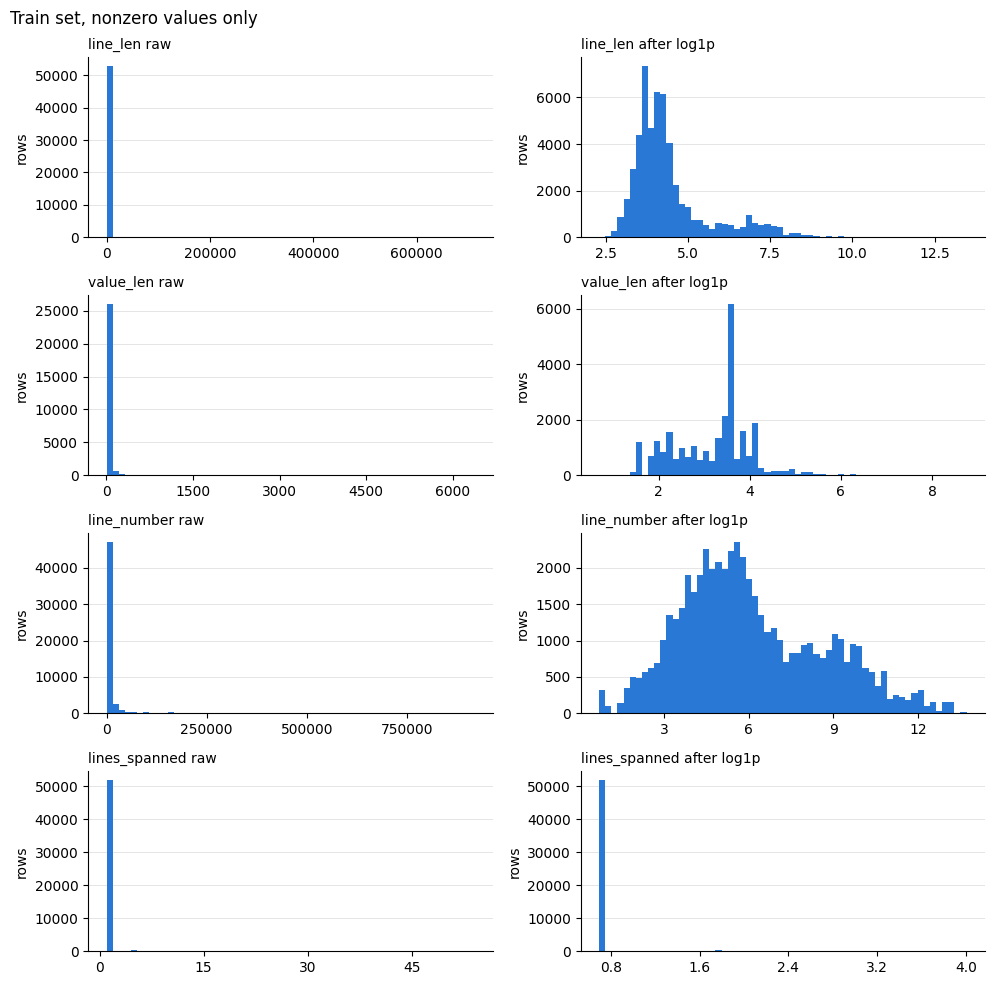

In [8]:
show_cols = ["line_len", "value_len", "line_number", "lines_spanned"]
fig, axes = plt.subplots(len(show_cols), 2, figsize=(10, 10))
for row, col in enumerate(show_cols):
    raw = X_train[col]
    # Empty values have length 0 and would hide the shape of the others, so only nonzero values are drawn
    raw = raw[raw > 0]
    axes[row, 0].hist(raw, bins=60, color=TRAIN_COLOR)
    axes[row, 0].set_title(col + " raw", loc="left", fontsize=10)
    axes[row, 1].hist(np.log1p(raw), bins=60, color=TRAIN_COLOR)
    axes[row, 1].set_title(col + " after log1p", loc="left", fontsize=10)
    for ax in axes[row]:
        # Fewer ticks keep the long numbers on the raw axis from running into each other
        ax.xaxis.set_major_locator(plt.MaxNLocator(5))
        ax.set_ylabel("rows")
        ax.grid(axis="y", color="#e0e0e0", linewidth=0.6)
        ax.set_axisbelow(True)
fig.suptitle("Train set, nonzero values only", x=0.01, ha="left")
fig.tight_layout()
plt.show()

On the raw axis almost every row falls in the first bar, because a few huge values stretch the axis. After the transform `line_len` and `line_number` show their real shape. `value_len` has a tall peak near 3.6, which is `log1p` of 36, the most common value length in train (5,464 rows) and the length of a UUID. `lines_spanned` is still one bar at a single line.

We apply `log1p` to the length and position measures listed below. The ratios already lie between 0 and 1, entropy is close to balanced, and path depth is a small count, so these are left as they are. The transform has no fitted parameters, so it is safe to apply to both sets.

In [9]:
LOG_COLS = ["value_len", "line_len", "line_number", "lines_spanned", "var_name_len"]
X_train_log = X_train.copy()
X_test_log = X_test.copy()
X_train_log[LOG_COLS] = np.log1p(X_train_log[LOG_COLS])
X_test_log[LOG_COLS] = np.log1p(X_test_log[LOG_COLS])
print("columns transformed:", LOG_COLS)
print("largest train value after the transform:", round(X_train_log[LOG_COLS].max().max(), 3))

columns transformed: ['value_len', 'line_len', 'line_number', 'lines_spanned', 'var_name_len']
largest train value after the transform: 13.729


After the transform the largest value in any of these columns is 13.73, down from 917,380 for `line_number`, so no single row can dominate the scale.